# BCA in a two-step discrete world (exploratory demo)
**Exploratory demo.** A tiny world for watching mechanisms at work. It is not a test of BCA on any benchmark, and no claims of improvement are baked in.

**Run All** with Python 3, NumPy and Matplotlib. No downloads, ML libraries or repository imports. All model, learning, calibration, tests and plots are embedded. Default workload: 600 training episodes, 300 calibration episodes, 2,000 test episodes and 1,000 bootstrap draws per stage.

This is a deliberately small *diagnostic adapter*, not a reproduction of a continuous-control host. BCA (Bayesian Conformal Aggregation) means the maximum of an empirical residual threshold and a Bayesian-bootstrap credible threshold. It does not mean that a Bellman-residual interval is a confidence interval for true Q, or that a policy using its width has a return guarantee.

**Start here:** change `SEED`, `N_TRAIN`, `P_TEST`, `UNKNOWN_PRIOR`, or `PENALTY_GAIN` below, then re-run from cell 1 (Restart and Run All). Running cells one at a time advances the random streams, so the numbers change. The optional seed sweep is disabled.
- `SEED = 7` is a demo seed. Its numbers have already been seen and discussed, so on their own they are not evidence. The optional sweep at the end shows how typical they are.
- `N_TRAIN` below about 100 can stop at cell 3 (the code cell under *World and data collection*), in about 1 seed in 5 at `N_TRAIN = 30`. A calibration episode then lands on a (stage, context, action) combination that has no training data, and the notebook stops rather than certify it. The error message names the combination.

In [1]:
import time, math, itertools
import numpy as np
import matplotlib.pyplot as plt
START = time.perf_counter()
SEED = 7                      # demo seed (already seen); see the note above
N_TRAIN, N_CAL, N_TEST = 600, 300, 2000
DRAWS = 1000
ALPHA, BETA = 0.1, 0.95
P_CAL = np.array([0.85, 0.15])
P_TEST = np.array([0.35, 0.65])
UNKNOWN_PRIOR = 2.5
SCALE_FLOOR = 0.02
PENALTY_GAIN = 1.0
RUN_SWEEP = False
N_SWEEP = 200                 # seeds in the optional sweep (cell 14)
# Independent SeedSequence children: never split transitions from the same episode.
streams = [np.random.default_rng(s) for s in np.random.SeedSequence(SEED).spawn(6)]
train_rng, cal_rng, test_rng, novel_rng, boot_rng, spare_rng = streams
assert 0 < ALPHA < 1 and 0 < BETA < 1, "ALPHA and BETA must lie strictly between 0 and 1"
assert np.all(P_CAL > 0) and np.all(P_TEST > 0), \
    "P_CAL and P_TEST must be > 0 for every context (finite likelihood ratio)"
assert np.isclose(P_CAL.sum(), 1) and np.isclose(P_TEST.sum(), 1), "P_CAL and P_TEST must each sum to 1"



## World and data collection
State is `(t,c)`: decision time t=0 or 1, fixed observed context c=0 or 1; terminal after t=1. Thus four decision states plus terminal. Actions: 0 = safe, 1 = venture. Discount is 1.

| t | context | action 0 outcomes | action 1 outcomes | next |
|---|---|---|---|---|
| 0 | 0 | reward 0.1 | reward 0.3 | (1,0) |
| 0 | 1 | reward 0.1 | reward -0.5 / 1.1, probability 1/2 each | (1,1) |
| 1 | 0 | reward 1 | reward 0 / 3, probability 1/2 each | terminal |
| 1 | 1 | reward 1 | **withheld**: harmful: -5 / 2 with probabilities .8 / .2; harmless: reward 2 | terminal |

Behavior chooses action 1 with probability .5 at t=0, .25 at (1,0), and **zero** at (1,1) (the table `P_VENTURE` in the code).
Train/calibration contexts follow P_CAL. The supported test uses P_TEST with the **same behavior actions and transition/reward law**. Hence the known likelihood ratio is w(c)=P_TEST(c)/P_CAL(c), at both stages. This is support-preserving context-frequency shift, not policy-shift coverage. A separate novelty probe forces the withheld pair; no importance ratio or finite certificate exists there.

Rewards at different steps are independently drawn conditional on context/actions. Failure is precisely the event terminal reward < 0. It is an evaluation outcome, never a learning feature.

**The two steps are independent one-step choices.** The step-0 action does not change the next state. The step-0 target adds the critic's value for the safe step-1 action, which is exactly 1 because that action always pays 1. So no critic error passes back from step 1 into step 0, and the step-1 choice cannot change step-0 rankings. This world therefore cannot show how a critic's errors spread backwards through its own targets ("bootstrapping": building a target from the critic's estimate of the next value), the main failure mode in offline reinforcement learning.


In [2]:
def outcomes(t, c, a, variant="harmful"):
    # Simulator/oracle only. Learner receives sampled (c,a,r), not this table.
    if t == 0:
        if a == 0: return [(1., .1)]
        return [(1., .3)] if c == 0 else [(.5, -.5), (.5, 1.1)]
    if a == 0: return [(1., 1.)]
    if c == 0: return [(.5, 0.), (.5, 3.)]
    return [(.8, -5.), (.2, 2.)] if variant == "harmful" else [(1., 2.)]

# Behavior policy: probability of the venture (action 1) at [stage t, context c].
P_VENTURE = np.array([[.5, .5], [.25, 0.]])

def episodes(n, p, rng, variant="harmful", novel=False):
    c = rng.choice(2, n, p=p)
    a = np.zeros((n, 2), dtype=int)
    for t in range(2):
        a[:, t] = rng.binomial(1, P_VENTURE[t, c])
    if novel:
        c[:] = 1
        a[:, 1] = 1
    r = np.zeros((n, 2))
    for i in range(n):
        for t in range(2):
            o = outcomes(t, int(c[i]), int(a[i,t]), variant)
            k = rng.choice(len(o), p=[x[0] for x in o])
            r[i,t] = o[k][1]
    return {"c": c, "a": a, "r": r}

train = episodes(N_TRAIN, P_CAL, train_rng)
cal = episodes(N_CAL, P_CAL, cal_rng)
test = episodes(N_TEST, P_TEST, test_rng)
novel = episodes(N_TEST, P_TEST, novel_rng, novel=True)

def fit_tabular(data):
    q = np.full((2,2,2), UNKNOWN_PRIOR, dtype=float)
    counts = np.zeros((2,2,2), dtype=int)
    # Fixed continuation policy pi0(c)=safe at stage 1.
    # Fit terminal means then frozen bootstrapped stage-0 targets on training only.
    for t in (1,0):
        for c in range(2):
            for a in range(2):
                mask = (data["c"] == c) & (data["a"][:,t] == a)
                counts[t,c,a] = mask.sum()
                if mask.any():
                    y = data["r"][mask,t].copy()
                    if t == 0: y += q[1,c,0]
                    q[t,c,a] = y.mean()
    # Sparse cells have a larger heuristic scale. This is NOT an estimated SE.
    scale = np.maximum(SCALE_FLOOR, 1 / np.sqrt(np.maximum(counts, 1)))
    return q, counts, scale

q, counts, scale = fit_tabular(train)
supported = counts > 0
print("Training counts [time, context, action]:\n", counts)
print("Frozen critic:\n", q)
print("Train-only count scales:\n", scale)

def targets(data, t):
    y = data["r"][:,t].copy()
    if t == 0: y += q[1,data["c"],0]
    return y

# Cells with a certain outcome should have residual exactly 0, but the fitted mean of
# identical rewards can be off by about 1e-16. Snap such floating-point dust to 0.
RESID_TOL = 1e-9
def snap(r):
    return np.where(r < RESID_TOL, 0., r)

def residual(data, t):
    c, a = data["c"], data["a"][:,t]
    return snap(np.abs(targets(data,t) - q[t,c,a]))

def scores(data, t):
    c, a = data["c"], data["a"][:,t]
    bad = ~supported[t,c,a]
    if bad.any():
        missing = sorted({(t,int(ci),int(ai)) for ci,ai in zip(c[bad],a[bad])})
        raise ValueError(f"Calibration cells {missing} [t,c,a] have no training data; "
                         "increase N_TRAIN or change SEED (refusing to certify unseen cells).")
    return residual(data,t) / scale[t,c,a]

cal_scores = [scores(cal,t) for t in range(2)]



Training counts [time, context, action]:
 [[[263 240]
  [ 53  44]]

 [[396 107]
  [ 97   0]]]
Frozen critic:
 [[[1.1        1.3       ]
  [1.1        1.44545455]]

 [[1.         1.62616822]
  [1.         2.5       ]]]
Train-only count scales:
 [[[0.06166264 0.06454972]
  [0.13736056 0.15075567]]

 [[0.05025189 0.09667365]
  [0.10153462 1.        ]]]


The unknown cell is initialized to `UNKNOWN_PRIOR` (default 2.5), an intentionally optimistic **declared prior**, not an observation. It stays there. No-penalty can exploit that arbitrary prior. Refusal methods never certify it. A count-only scale max(SCALE_FLOOR,1/sqrt(n)) supplies action-dependent widths without hidden hazards or oracle Q. At n=1 it is 1; at n=0 its numerical value is unused because support refusal takes precedence. It measures sparse-data caution heuristically, not posterior uncertainty. If a calibration episode falls in a cell with no training data, calibration stops with an error naming that cell, rather than silently assigning confidence.

Residuals below `RESID_TOL` = 1e-9 are set to exactly 0. Cells with a certain outcome should have zero residual, but the fitted mean of identical rewards can be off by about 1e-16 from rounding. Without this snap, those rounding values, not data, would set the stage-0 threshold.

The critic and safe continuation policy are frozen before calibration. Calibrate **separately by stage**, with one score per independent episode at each stage. Scores across stages are correlated, so these are marginal stage-wise diagnostics, not simultaneous trajectory coverage.


## Calibration semantics and provenance
Inspected 2026-10-14: [BCA calibration/wbcp.py](https://github.com/dbayha7/BCA/blob/main/calibration/wbcp.py), [repository overview](https://github.com/dbayha7/BCA). The repository cites Lou and Luo, *Weighted Bayesian Conformal Prediction*, arXiv:2604.06464v3, Algorithm 1. The following compact NumPy implementation follows its threshold semantics; it is not a copied host training pipeline.

For sorted scores s_i and likelihood ratios w_i:
- Empirical threshold: smallest score whose cumulative weight reaches (1-alpha) sum(w_i), **without** a test atom.
- Posterior: independent E_i ~ Exp(1); masses w_i E_i plus a worst-case +infinity atom of mass wbar E_(n+1), with **wbar=E_test[w(c)]**, not w(query). Select each draw's (1-alpha) crossing, then its beta order statistic. BCA is max(empirical, credible). Infinite credible thresholds remain refusals.
- Uniform weights and wbar=1 recover the unweighted algorithm. Production README currently uses uniform weights; this known-ratio experiment is a declared toy extension.
- Separate split conformal baseline adds a +infinity atom with **query** weight w(c_query). This gives the usual finite-sample rank correction at unit weights. It is **not** the repository's empirical term and is not inserted into the repository BCA formula.

Bootstrap thresholds are Monte Carlo estimates with DRAWS draws, not exact Bayesian integrals. We use ordinary floating-point cumulative sums; production additionally resolves empirical equality boundaries with exact rational arithmetic. No weighted coverage theorem for the BCA adapter is asserted here. Query-weighted conformal's marginal target concerns supported behavior queries under the stated covariate shift, not a greedy learned policy.


In [3]:
def weighted_quantile(s, w, level, extra=0.):
    s, w = np.asarray(s), np.asarray(w)
    order = np.argsort(s, kind="stable")
    s, w = s[order], w[order]
    target = level * (w.sum() + extra)
    k = np.searchsorted(np.cumsum(w), target, side="left")
    return float(s[k]) if k < len(s) else np.inf

def bca_threshold(s, rng, weights=None, test_mass=1., draws=DRAWS):
    s = np.asarray(s, float)
    w = np.ones(len(s)) if weights is None else np.asarray(weights, float)
    assert len(s) and np.all(np.isfinite(s))
    assert np.all(np.isfinite(w)) and np.all(w > 0) and test_mass > 0
    order = np.argsort(s, kind="stable")
    s, w = s[order], w[order]
    empirical = weighted_quantile(s, w, 1-ALPHA)
    crossings = []
    # Small bounded batches.
    for start in range(0, draws, 128):
        e = rng.exponential(size=(min(128,draws-start),len(s)+1))
        mass = e[:,:-1] * w
        total = mass.sum(axis=1) + test_mass * e[:,-1]
        hit = np.cumsum(mass,axis=1) >= (1-ALPHA)*total[:,None]
        crossings.extend(np.where(hit.any(axis=1), s[hit.argmax(axis=1)], np.inf))
    crossings = np.sort(crossings)
    credible = float(crossings[math.ceil(BETA*draws)-1])
    return max(empirical,credible), empirical, credible

ratio = P_TEST / P_CAL
wbar = float(P_TEST @ ratio)
cal_weights = ratio[cal["c"]]
thresholds = {name:np.zeros((2,2)) for name in
              ("empirical", "conformal", "BCA", "weighted empirical",
               "weighted conformal", "weighted BCA")}
details = []
for t,s in enumerate(cal_scores):
    b, e, cr = bca_threshold(s, boot_rng)
    wb, we, wcr = bca_threshold(s, boot_rng, cal_weights, wbar)
    for c in range(2):
        thresholds["empirical"][t,c] = e
        thresholds["BCA"][t,c] = b
        thresholds["weighted empirical"][t,c] = we
        thresholds["weighted BCA"][t,c] = wb
        thresholds["conformal"][t,c] = weighted_quantile(s,np.ones(len(s)),1-ALPHA,1.)
        thresholds["weighted conformal"][t,c] = weighted_quantile(s,cal_weights,1-ALPHA,ratio[c])
    details.append((t,e,cr,b,we,wcr,wb))
print("Known context ratios:", ratio, "  E_test[w] =", wbar)
print("stage, empirical, credible, BCA, weighted empirical, weighted credible, weighted BCA")
for row in details: print(tuple(round(x,4) for x in row))

def widths(name):
    out = thresholds[name][:,:,None] * scale
    return np.where(supported, out, np.inf)



Known context ratios: [0.41176471 4.33333333]   E_test[w] = 2.960784313725491
stage, empirical, credible, BCA, weighted empirical, weighted credible, weighted BCA
(0, 0.0, 0.0, 0.0, 4.3418, 6.2714, 6.2714)
(1, 16.8212, 16.8212, 16.8212, 14.211, 14.211, 14.211)


## Keep three questions separate
1. **Frozen one-step target coverage:** is sampled Y=r+Qhat(next,safe) inside Qhat ± width? Report finite coverage, refusal rate and mean finite full width separately. Infinite intervals are **excluded** from finite coverage and reported as refusals. Coverage is checked in score space, |Y-Qhat|/scale <= threshold, the quantity the threshold was selected on. The *sampled* column uses the 2,000 test episodes. The *exact* column computes the same coverage from the outcome table, the behavior probabilities and P_TEST, with no sampling; the sampled column is a cross-check.
2. **True mean-Q error (oracle diagnostic):** compare Qhat to exact Q^safe, for the same fixed continuation. Finite interval containment here is descriptive; it is not what calibration guarantees.
3. **Policy performance (oracle evaluation):** exact expected sum of two rewards under the actually selected actions. Regret = optimal expected return minus that return, with the same initial context distribution. Failure risk = probability of terminal reward < 0. No sampled returns enter these evaluations.

**How coarse the coverage numbers are.** Among behavior queries, each stage has just one cell with a random outcome (two possible rewards); every other cell's residual is exactly 0. So under the default P_TEST a stage's exact coverage can take only three values: 0.675, 0.8375 or 1 at stage 0, and 0.9125, 0.95625 or 1 at stage 1. Stage-1 coverage under P_TEST therefore cannot fall below 0.9 for any method; stage 0 is the informative test. Widths in cells with a certain outcome are just the stage's threshold times the count scale. They are not calibrated quantities for those cells.

The test episodes stay untouched until diagnostics. Novelty is shown separately, never pooled into supported coverage.


In [4]:
def coverage_report(data, name, t):
    c,a = data["c"],data["a"][:,t]
    h = widths(name)[t,c,a]
    finite = np.isfinite(h)
    # Compare in score space, the quantity the threshold was selected on.
    covered = residual(data,t) / scale[t,c,a] <= thresholds[name][t,c]
    cov = covered[finite].mean() if finite.any() else np.nan
    width = (2*h[finite]).mean() if finite.any() else np.nan
    return cov, 1-finite.mean(), width

def exact_coverage(name, t, p=P_TEST, variant="harmful"):
    # The same three numbers as coverage_report, computed exactly from the outcome
    # table, the behavior probabilities P_VENTURE and the context law p. No sampling.
    h = widths(name)
    finite_mass = covered_mass = width_mass = 0.
    for c in range(2):
        for a in range(2):
            mass = p[c] * (P_VENTURE[t,c] if a == 1 else 1 - P_VENTURE[t,c])
            if mass == 0 or not np.isfinite(h[t,c,a]):
                continue
            finite_mass += mass
            width_mass += mass * 2 * h[t,c,a]
            for prob, r in outcomes(t, c, a, variant):
                y = r + q[1,c,0] if t == 0 else r
                score = snap(np.abs(y - q[t,c,a])) / scale[t,c,a]
                covered_mass += mass * prob * (score <= thresholds[name][t,c])
    if finite_mass == 0:
        return np.nan, 1., np.nan
    return covered_mass / finite_mass, 1 - finite_mass, width_mass / finite_mass

print("Supported shifted test: method | stage | finite coverage: sampled, exact | refusal | mean finite full width")
for name in thresholds:
    for t in range(2):
        cv,rf,wi = coverage_report(test,name,t)
        print(f"{name:20} {t}  {cv:.3f}  {exact_coverage(name,t)[0]:.4f}  {rf:.3f}  {wi:.3f}")
print("\nNo-shift control, exact (contexts from P_CAL): method | stage 0 | stage 1")
for name in ("empirical","conformal","BCA"):
    print(f"{name:20} {exact_coverage(name,0,P_CAL)[0]:.4f}  {exact_coverage(name,1,P_CAL)[0]:.4f}")
print("\nNovelty probe, terminal stage (NaN means no finite certificate):")
for name in ("conformal","BCA","weighted conformal","weighted BCA"):
    cv,rf,wi = coverage_report(novel,name,1)
    print(f"{name:20} refusal={rf:.3f}  finite coverage={cv}  width={wi}")

# ORACLE: exact dynamic programming. Only diagnostics below use outcomes().
def oracle_q(variant, continuation=None):
    oq = np.zeros((2,2,2))
    for t in (1,0):
        for c in range(2):
            for a in range(2):
                oq[t,c,a] = sum(p*r for p,r in outcomes(t,c,a,variant))
                if t == 0:
                    oq[t,c,a] += (oq[1,c].max() if continuation is None
                                     else oq[1,c,continuation[c]])
    return oq

def exact_evaluate(policy, variant, p=P_TEST):
    value = np.zeros((2,2))
    failure = np.zeros(2)
    for c in range(2):
        a1 = int(policy[1,c])
        value[1,c] = sum(prob*r for prob,r in outcomes(1,c,a1,variant))
        failure[c] = sum(prob for prob,r in outcomes(1,c,a1,variant) if r < 0)
        value[0,c] = sum(prob*r for prob,r in outcomes(0,c,int(policy[0,c]),variant)) + value[1,c]
    ret = float(p @ value[0])
    optimum = float(p @ oracle_q(variant)[0].max(axis=-1))
    return ret, optimum-ret, float(p @ failure)

def make_policy(name):
    if name == "no penalty":
        utility = q.copy()
    elif name == "support only":
        utility = np.where(supported,q,-np.inf)
    elif name == "scale only":
        utility = np.where(supported,q-PENALTY_GAIN*scale,-np.inf)
    else:
        h = widths(name)
        utility = np.where(np.isfinite(h),q-PENALTY_GAIN*h,-np.inf)
    refused = ~np.isfinite(utility).any(axis=-1)
    # A tie: both actions finite and within RESID_TOL (floating-point dust counts as equal).
    ties = np.isfinite(utility).all(axis=-1) & np.isclose(utility[...,0], utility[...,1], rtol=0, atol=RESID_TOL)
    policy = utility.argmax(axis=-1)
    # SAME fallback: safe action 0 when every candidate is refused. Ties also go to 0.
    policy[refused | ties] = 0
    return policy,refused,ties

methods = ["no penalty","support only","scale only","conformal","BCA",
           "weighted conformal","weighted BCA"]
results = {}
for variant in ("harmful","harmless"):
    print("\nORACLE world:",variant)
    trueq = oracle_q(variant, continuation=np.zeros(2,dtype=int))
    print("True Q^safe:\n",trueq)
    for name in ("BCA","weighted BCA"):
        h = widths(name); finite = np.isfinite(h)
        contained = snap(np.abs(q-trueq)) / scale <= thresholds[name][:,:,None]   # score space
        print(name, "finite-cell Q^safe containment =",
              np.mean(contained[finite]),
              "finite-cell mean abs Q error =", np.mean(np.abs(q-trueq)[finite]))
    print("method | return | regret | failure risk | actions [t,c] | fallback states")
    results[variant] = []
    for name in methods:
        pi, fallback, ties = make_policy(name)
        metrics = exact_evaluate(pi,variant)
        results[variant].append(metrics)
        line = f"{name:20} {metrics[0]:7.3f} {metrics[1]:7.3f} {metrics[2]:7.3f} {pi.tolist()} {int(fallback.sum())}"
        if ties.any():
            line += f"  TIE at [t,c] {np.argwhere(ties).tolist()}, taken as safe"
        print(line)



Supported shifted test: method | stage | finite coverage: sampled, exact | refusal | mean finite full width
empirical            0  0.674  0.6750  0.000  0.000
empirical            1  1.000  1.0000  0.000  2.949
conformal            0  0.674  0.6750  0.000  0.000
conformal            1  1.000  1.0000  0.000  2.949
BCA                  0  0.674  0.6750  0.000  0.000
BCA                  1  1.000  1.0000  0.000  2.949
weighted empirical   0  0.842  0.8375  0.000  1.005
weighted empirical   1  0.955  0.9563  0.000  2.492
weighted conformal   0  0.842  0.8375  0.000  1.005
weighted conformal   1  0.955  0.9563  0.000  2.492
weighted BCA         0  1.000  1.0000  0.000  1.451
weighted BCA         1  0.955  0.9563  0.000  2.492

No-shift control, exact (contexts from P_CAL): method | stage 0 | stage 1
empirical            0.9250  1.0000
conformal            0.9250  1.0000
BCA                  0.9250  1.0000

Novelty probe, terminal stage (NaN means no finite certificate):
conformal          

Policy choice is a **toy lower-score rule** argmax(Qhat - gain × width), not the production BCA actor objective. All calibrated methods use the identical support mask and safe fallback as support-only. Within remaining support, they may choose differently from support-only because the count scale varies by action. Ties (utilities within 1e-9) are printed and go to the safe action 0.

**Calibration sets the strength of the count penalty, not where caution goes.** Every calibrated width is the count scale times one threshold per stage (per stage and context for weighted conformal). So within a decision state, a calibrated method ranks actions exactly as scale-only would if its multiplier were PENALTY_GAIN times that threshold. Any difference between them is a difference in strength only. Scale-only isolates the effect of count scaling at an arbitrary multiplier of 1. Compare it with support-only and calibrated methods before attributing a gain to calibration. A calibrated width might suppress a beneficial high-variance action and reduce return: the residuals behind the width are mostly reward noise (at (t=1, c=0) the venture pays 0 or 3).

The action-selection table does not inherit the behavior-query coverage result: greedy selection changes the query distribution and may target unsupported actions. Support refusal removes the same unobserved action in both worlds, potentially helping in the harmful world and hurting in the harmless one. The training data cannot tell these worlds apart.


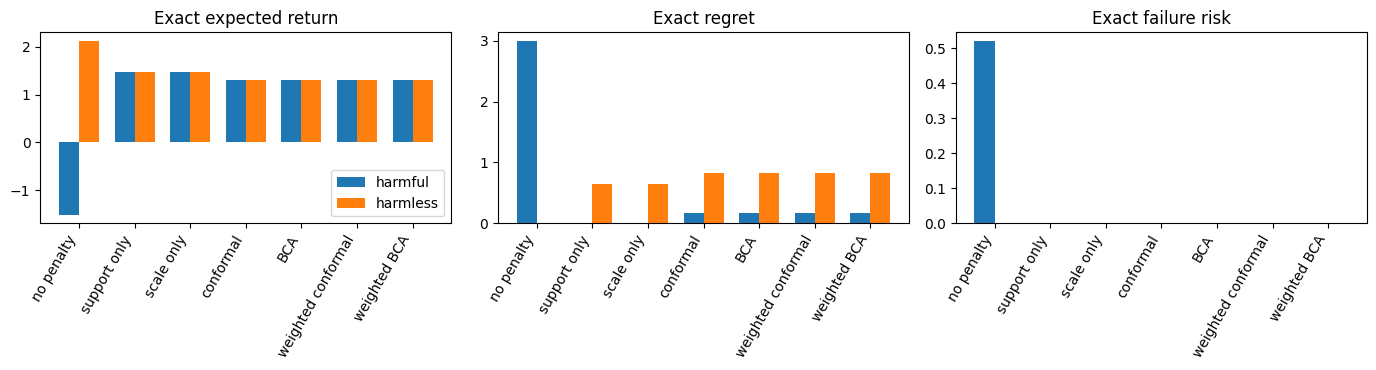

In [5]:
fig, axes = plt.subplots(1,3,figsize=(14,3.8))
x = np.arange(len(methods))
for k, (metric,title) in enumerate(zip(range(3),("Exact expected return","Exact regret","Exact failure risk"))):
    for offset,variant in ((-.18,"harmful"),(.18,"harmless")):
        vals = np.array(results[variant])[:,metric]
        axes[k].bar(x+offset, vals, .36, label=variant)
    axes[k].set_title(title)
    axes[k].set_xticks(x)
    axes[k].set_xticklabels(methods,rotation=60,ha="right")
axes[0].legend()
fig.tight_layout()
plt.show()



## Executable checks
These assertions check probability normalization, Bellman recursion, exhaustive policy evaluation, unit-weight identities, unknown-support refusal, identical observed data across the two worlds, the negative control (subtracting a global scalar from every action cannot change greedy rankings), and agreement between the exact and sampled coverage (within 5 standard errors). They do not assert that BCA must improve policy return. Some parts hold by construction and cannot fail here: the infinite width for an action with no training data (check 5), identical data in the two worlds (check 6: the default behavior never takes the withheld action) and the argmax algebra of check 7.

In [6]:
# 1. All discrete outcome probabilities normalize.
for variant,t,c,a in itertools.product(("harmful","harmless"),range(2),range(2),range(2)):
    oo = outcomes(t,c,a,variant)
    assert np.isclose(sum(p for p,r in oo),1) and all(p>=0 for p,r in oo)

# 2. Known support shift normalizes, and effective sample size is meaningful.
assert np.isclose(P_CAL @ ratio,1.)
assert np.isclose(P_TEST @ ratio,wbar)
ess = cal_weights.sum()**2 / (cal_weights @ cal_weights)
assert 0 < ess <= N_CAL+1e-8

# 3. Bellman identities and independent exhaustive outcome evaluation.
for variant in ("harmful","harmless"):
    oq = oracle_q(variant, np.zeros(2,dtype=int))
    for c,a in itertools.product(range(2),range(2)):
        assert np.isclose(oq[0,c,a],sum(p*r for p,r in outcomes(0,c,a,variant))+oq[1,c,0])
    all_returns = []
    for actions in itertools.product(range(2),repeat=4):
        pi = np.array(actions).reshape(2,2)
        ret = fail = 0.
        for c in range(2):
            for (p0,r0),(p1,r1) in itertools.product(
                outcomes(0,c,int(pi[0,c]),variant),outcomes(1,c,int(pi[1,c]),variant)):
                mass = P_TEST[c]*p0*p1
                ret += mass*(r0+r1)
                fail += mass*(r1<0)
        er,reg,ef = exact_evaluate(pi,variant)
        assert np.isclose(ret,er) and np.isclose(fail,ef) and reg>=-1e-10
        all_returns.append(ret)
    assert np.isclose(max(all_returns),P_TEST @ oracle_q(variant)[0].max(axis=-1))

# 4. Unit-weight BCA identity with identical draws; query CP becomes corrected rank.
s = cal_scores[0]
a = bca_threshold(s,np.random.default_rng(42))
b = bca_threshold(s,np.random.default_rng(42),np.ones(len(s)),1.)
assert np.array_equal(a,b)
cp = weighted_quantile(s,np.ones(len(s)),1-ALPHA,1.)
rank = math.ceil((len(s)+1)*(1-ALPHA))
expected = np.sort(s)[rank-1] if rank<=len(s) else np.inf
assert cp == expected

# 5. Unknown support never gets a finite interval, in either world.
assert counts[1,1,1] == 0 and q[1,1,1] == UNKNOWN_PRIOR
for name in thresholds:
    assert np.isinf(widths(name)[1,1,1])
    assert coverage_report(novel,name,1)[1] == 1.
for name in methods[1:]:
    assert make_policy(name)[0][1,1] == 0
# Even known support may refuse because a posterior/CP test atom is too large.
assert np.isinf(weighted_quantile([1.],[1.],.9,1.))
assert np.isinf(bca_threshold([1.],np.random.default_rng(1),draws=1000)[0])

# 6. Unobserved-world changes cannot change observed data or training/calibration.
d1 = episodes(100,P_CAL,np.random.default_rng(123),"harmful")
d2 = episodes(100,P_CAL,np.random.default_rng(123),"harmless")
assert all(np.array_equal(d1[k],d2[k]) for k in d1)

# 7. Global-penalty negative control, with and without the common support restriction.
assert np.array_equal(q.argmax(-1),(q-0.731).argmax(-1))
masked = np.where(supported,q,-np.inf)
assert np.array_equal(masked.argmax(-1),(masked-0.731).argmax(-1))
# 8. Exact coverage agrees with the sampled test coverage (within 5 standard errors).
for name in thresholds:
    for t in range(2):
        cv,rf,wi = coverage_report(test,name,t)
        ex = exact_coverage(name,t)[0]
        n_finite = round((1-rf)*N_TEST)
        if n_finite:
            assert abs(cv-ex) <= 5*math.sqrt(max(ex*(1-ex),0.)/n_finite) + 1e-12, (name,t,cv,ex)
print("All checks passed. Calibration effective sample size (ESS):",round(ess,2))
print("Main notebook elapsed seconds:",round(time.perf_counter()-START,3))



All checks passed. Calibration effective sample size (ESS): 97.22
Main notebook elapsed seconds: 1.147


## Optional seed sweep (disabled)
Set `RUN_SWEEP = True` in cell 1, then Restart and Run All. For each of `N_SWEEP` seeds (default 200) the sweep regenerates training and calibration data, refits the critic and recalibrates. It reports, all computed exactly from the outcome table (no sampled test set):
- the expected return of every method in both worlds, and the paired differences BCA minus support-only and weighted BCA minus support-only (same seed, same data), with counts of seeds where the method does better, ties or does worse;
- the stage-wise coverage of every calibrated method under P_TEST, and the share of seeds whose stage-0 coverage reaches 0.90;
- a no-shift control: the unweighted methods' coverage when contexts follow P_CAL.

Seeds whose calibration data hit a (stage, context, action) combination with no training data are skipped and listed. Seed k uses `np.random.SeedSequence([20261014, k])`, separate from the demo seed's stream. Seeds k = 0 to 199 were run on 14 Oct 2026, so they are seen: they cannot serve as fresh seeds for a confirmatory test. The sweep describes seed-to-seed spread; it is not a significance test. Compare paired differences rather than picking a lucky seed. It ran in 4 to 10 seconds on the machine that produced the stored outputs. The main run's variables are restored afterwards, even if a seed fails.

In [7]:
if RUN_SWEEP:
    sweep_start = time.perf_counter()
    saved = (q,counts,scale,supported,thresholds)
    calibrated = list(thresholds)                       # the six threshold methods
    unweighted = ["empirical","conformal","BCA"]
    worlds = ("harmful","harmless")
    ret, cov_test, cov_cal, kept, skipped, tie_log = [], [], [], [], [], []
    try:
        for seed in range(N_SWEEP):
            rs = [np.random.default_rng(x) for x in np.random.SeedSequence([20261014, seed]).spawn(3)]
            tr = episodes(N_TRAIN,P_CAL,rs[0])
            ca = episodes(N_CAL,P_CAL,rs[1])
            q,counts,scale = fit_tabular(tr)
            supported = counts>0
            if not all(supported[t,ca["c"],ca["a"][:,t]].all() for t in range(2)):
                skipped.append(seed); continue
            thresholds = {name:np.zeros((2,2)) for name in calibrated}
            w = ratio[ca["c"]]
            for t in range(2):
                s = scores(ca,t)
                bb,ee,cc = bca_threshold(s,rs[2])
                wb,we,wc = bca_threshold(s,rs[2],w,wbar)
                for c in range(2):
                    for name,val in (("BCA",bb),("empirical",ee),("weighted BCA",wb),("weighted empirical",we),
                                     ("conformal",weighted_quantile(s,np.ones(len(s)),1-ALPHA,1)),
                                     ("weighted conformal",weighted_quantile(s,w,1-ALPHA,ratio[c]))):
                        thresholds[name][t,c] = val
            policies = [make_policy(name) for name in methods]
            kept.append(seed)
            tied = [name for name,pt in zip(methods,policies) if pt[2].any()]
            if tied: tie_log.append((seed,tied))
            ret.append([[exact_evaluate(pt[0],v)[0] for pt in policies] for v in worlds])
            cov_test.append([[exact_coverage(name,t) for t in range(2)] for name in calibrated])
            cov_cal.append([[exact_coverage(name,t,P_CAL) for t in range(2)] for name in unweighted])
    finally:
        q,counts,scale,supported,thresholds = saved
    print(f"Sweep: {len(kept)} of {N_SWEEP} seeds used; seed k uses SeedSequence([20261014, k]).")
    if skipped:
        print(f"Skipped {len(skipped)} seeds (a calibration cell had no training data):", skipped)
    if kept:
        ret = np.array(ret)                             # [seed, world, method]
        cov_test = np.array(cov_test)                   # [seed, method, stage, (coverage, refusal, width)]
        cov_cal = np.array(cov_cal)
        print(f"Seeds with a tie in some method's choice (taken as safe): {len(tie_log)}", tie_log[:5])
        print("\nExact return, mean over seeds: method | harmful | harmless")
        for m,name in enumerate(methods):
            print(f"{name:20} {ret[:,0,m].mean():7.3f} {ret[:,1,m].mean():7.3f}")
        print("\nPaired return difference (same seed, same data): mean | seeds better / tied / worse")
        so = methods.index("support only")
        for k,v in enumerate(worlds):
            for name in ("BCA","weighted BCA"):
                d = ret[:,k,methods.index(name)] - ret[:,k,so]
                print(f"{v:8} {name+' minus support only':33} {d.mean():+.3f} | "
                      f"{(d>1e-9).sum()} / {(abs(d)<=1e-9).sum()} / {(d<-1e-9).sum()}")
        print("\nExact finite coverage under P_TEST, mean over seeds:")
        print("method | stage 0 | stage 1 | share of seeds with stage 0 >= 0.90")
        for m,name in enumerate(calibrated):
            c0 = cov_test[:,m,0,0]
            print(f"{name:20} {np.nanmean(c0):.4f}  {np.nanmean(cov_test[:,m,1,0]):.4f}  {np.mean(c0 >= 0.9-1e-9):.3f}")
        print("\nNo-shift control, contexts from P_CAL (unweighted methods), same columns:")
        for m,name in enumerate(unweighted):
            c0 = cov_cal[:,m,0,0]
            print(f"{name:20} {np.nanmean(c0):.4f}  {np.nanmean(cov_cal[:,m,1,0]):.4f}  {np.mean(c0 >= 0.9-1e-9):.3f}")
        print("Largest exact refusal rate in any seed, method and stage:",
              round(float(max(cov_test[...,1].max(), cov_cal[...,1].max())),3))
    print("Sweep seconds:", round(time.perf_counter()-sweep_start,1))
else:
    print("Optional seed sweep skipped.")

Optional seed sweep skipped.


## Reading the result
- Check refusal before coverage: 100% novelty refusal is honest ignorance, not 100% coverage. It is also true by construction: an action with no training data always gets an infinite width, whatever the calibration does. So it says nothing about BCA in particular.
- Compare BCA with conformal and empirical thresholds, and weighted with unweighted on the **supported shifted** test. Read the exact column; the sampled one is a cross-check. Stage 0 is the informative stage.
- One seed is one draw. Seed 7's coverage and return gaps need not be typical; the sweep shows the spread over seeds. For example, at seed 7 weighted conformal misses 0.90 at stage 0 (exact 0.8375), yet in the sweep with default settings it reaches 0.90 in 191 of 200 seeds.
- A larger threshold can change width without changing discrete action choices. Ties are printed as ties.
- Compare policy returns with support-only using exactly the same fallback, and scale-only with the same count scale.
- True Q and policy outcomes are oracle diagnostics only. This tiny world isolates mechanisms; it does not establish a safety or return theorem for reinforcement learning.

**Execution status:** the stored outputs come from one Restart and Run All with the default settings, in a Jupyter kernel (nbclient; Python 3.10, NumPy 2.2), on 14 Oct 2026. An empty-output notebook is unexecuted. The optional sweep stays skipped unless RUN_SWEEP is set to True.